## 4. Functional Enrichment
## Gene Ontology Enrichment Analysis

Gene Ontology (GO) term enrichment is a technique to understand the roles and functions of different genes within a given set of genes. GO categorizes genes into specific groups based on their functions. These categories include biological processes (BP), molecular functions (MF), and cellular components (CC). Enrichment analysis checks if certain GO categories are overrepresented or significantly enriched in your list of genes compared to what you'd typically find in all genes.

For more information: [Gene Ontology: tool for the unification of biology](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3037419/)

A lot of online tools and R packages are available to perform GO enrichment analysis.


In this tutorial, we use [ShinyGO 0.77](http://bioinformatics.sdstate.edu/go/), a user-friendly interactive web-based tool to demonstrate Gene Ontology Enrichment analysis for the differentially expressed genes. ShinyGO is a powerful graphical interface that integrates a variety of databases like NCBI, UniProt, KEGG, GO, Biocarta, REACTOME and STRING. By inputting a set of genes, ShinyGO combine the data from these databases to provide meaningful information regarding the functions and pathways associated with the provided gene set.

Refer the following paper for more details about [ShinyGO](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7178415/).

Click [here](http://bioinformatics.sdstate.edu/go/) to go to the home page of ShinyGO.
Here is a snapshot of ShinyGO home page.

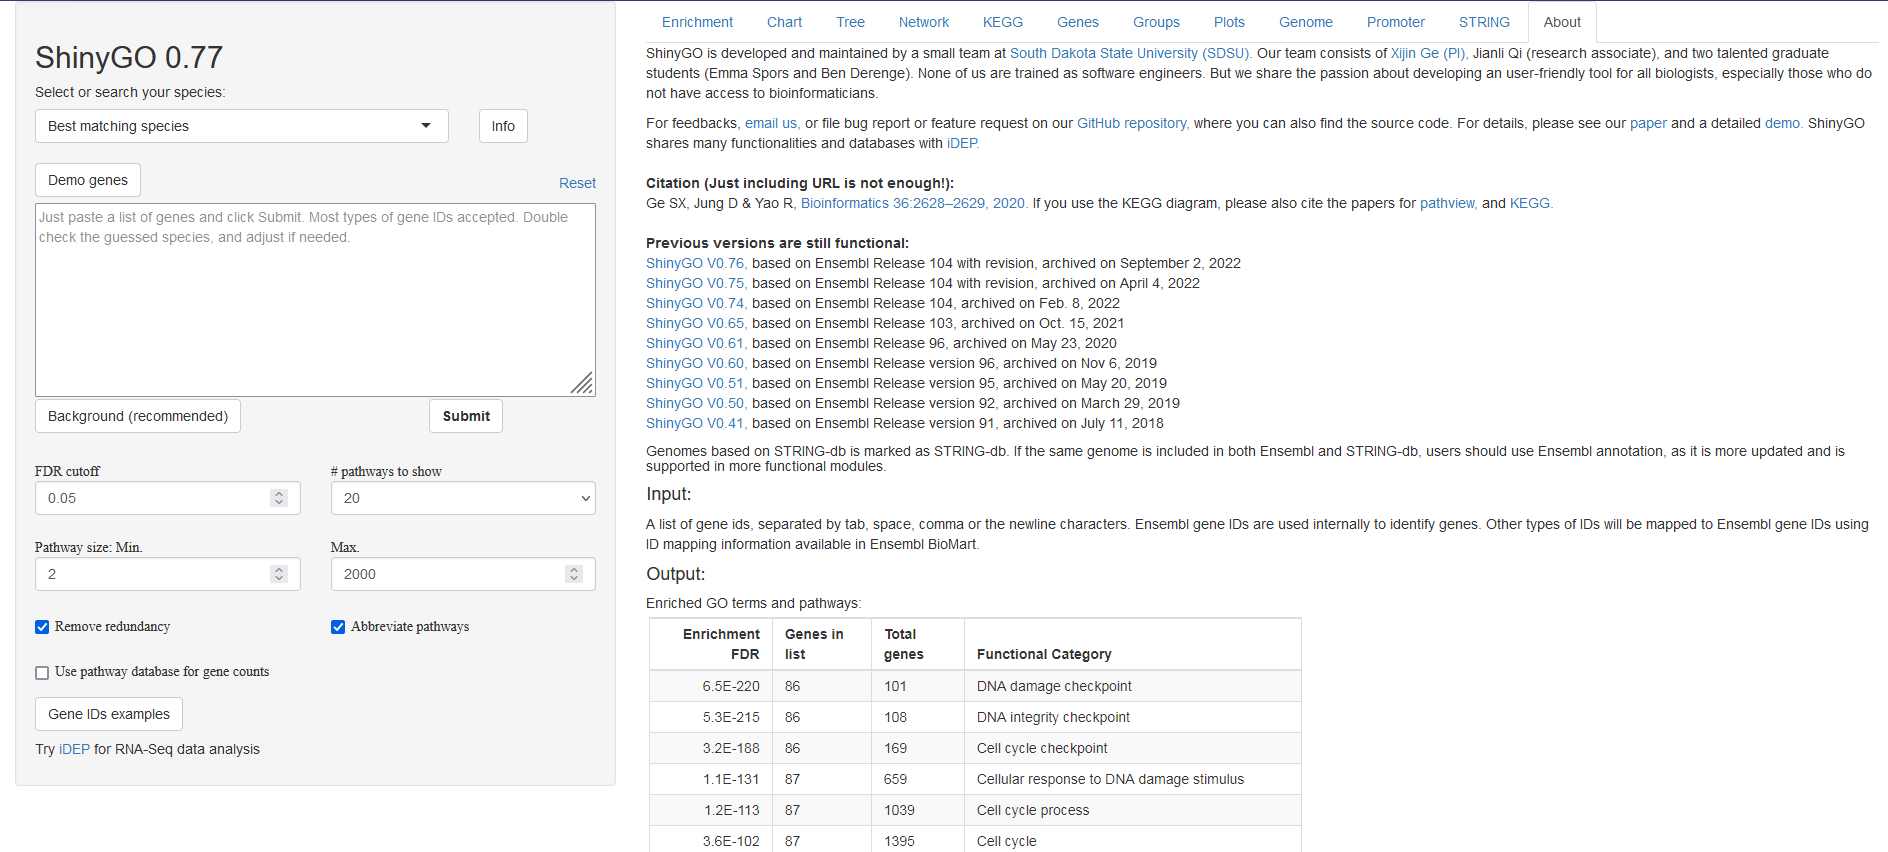


The provided R script serves to organize the list of upregulated and downregulated genes designated as inputs for ShinyGO. Significant Differentially Expressed Genes (DEGs) are filtered based on an FDR cutoff of 0.05 or lower. Upregulated genes are identified by a logFC value of 1, while downregulated genes are identified by a logFC value of -1. This process ensures the selection of genes meeting specific significance criteria before being utilized in ShinyGO.

In [1]:
%%R
deg_table <- read.csv("dge.csv", sep = ",", header = T, row.names = 1)
signif_degs <- deg_table[deg_table$FDR <= 0.05,] #putting FDR threshold of 0.05 and less
upreg_genes <- row.names(signif_degs[signif_degs$logFC > 1,])  #up regulated genes
downreg_genes <- row.names(signif_degs[signif_degs$logFC < (-1),])  #down regulated genes
write.table(upreg_genes, "upreg_genes.txt", quote=F, row.names=F, col.names=F)
write.table(downreg_genes, "downreg_genes.txt", quote=F, row.names=F, col.names=F)

UsageError: Cell magic `%%R` not found.


**1. Choose the organism as "Escherichia coli K12 substr. MG1655 STRINGdb" from the dropdown menu provided.**


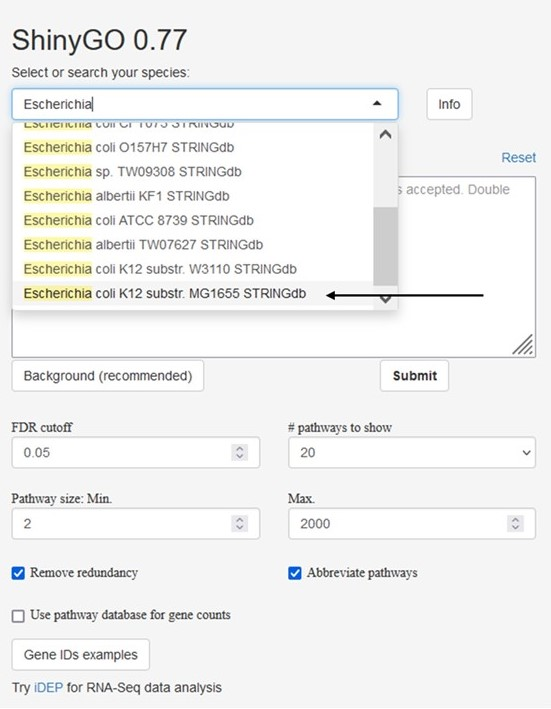


The R script saves upregulated and downregulated gene lists in separate files on your drive.

**2. Copy the content from the file containing upregulated genes and paste it in the text box provided below.**

Additionally, ShinyGO offers the option to include background genes, encompassing all measured gene expressions.

**3. To use this feature, copy all the gene IDs from the logFC file and paste them into the text box that appears when you select the "background (recommended)" option.**

Feel free to adjust parameters like the FDR cutoff or the number of pathways displayed before submitting your selection.

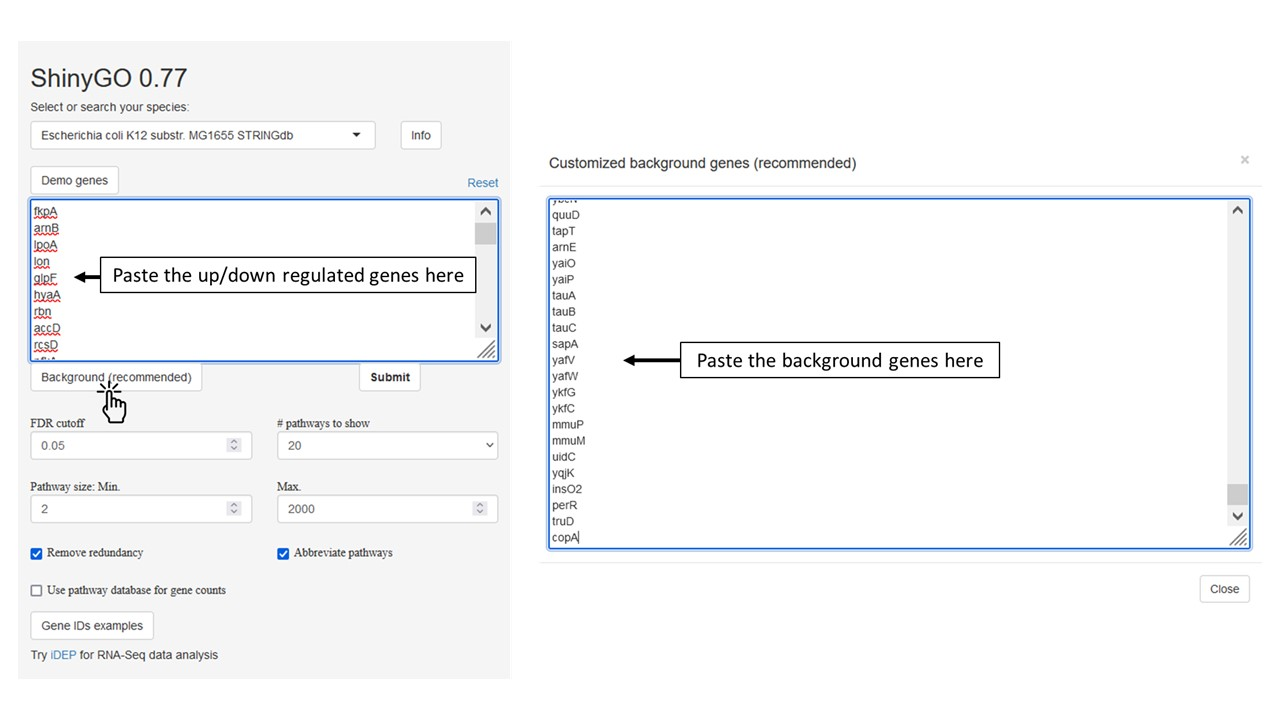


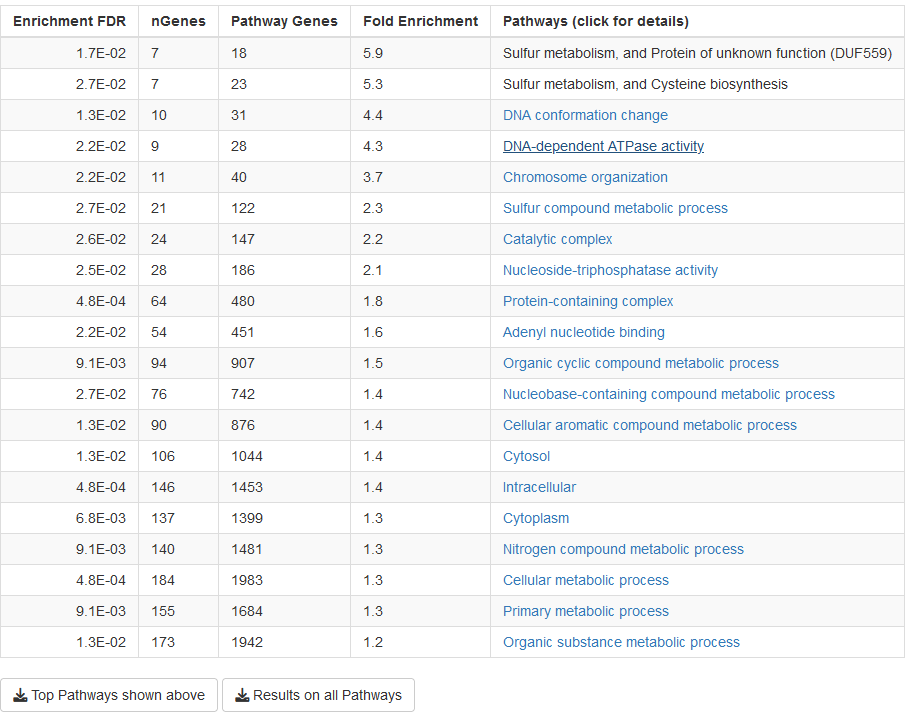

Upon clicking 'submit', ShinyGO performs enrichment calculations, presenting a table featuring FDR values, the count of up/down regulated genes engaged in the enriched pathway, total genes within the pathway, fold enrichment, and a pathway description, as displayed in the screenshot above.


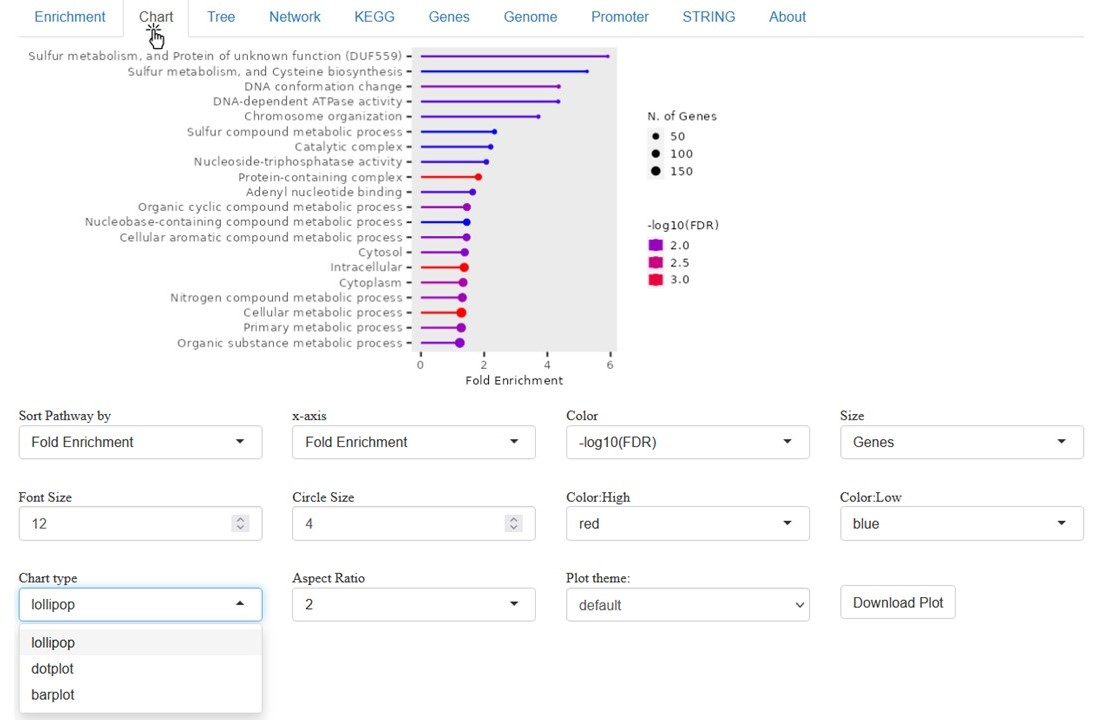




Clicking on the 'chart' tab enables visual representation via a lollipop plot. This graph displays pathway descriptions along the y-axis and fold enrichment along the x-axis. Circle sizes depict the number of genes within each pathway, while line colors correspond to FDR values. Additionally, users can alter the chart type to dotplot or barplot for alternative visualizations.



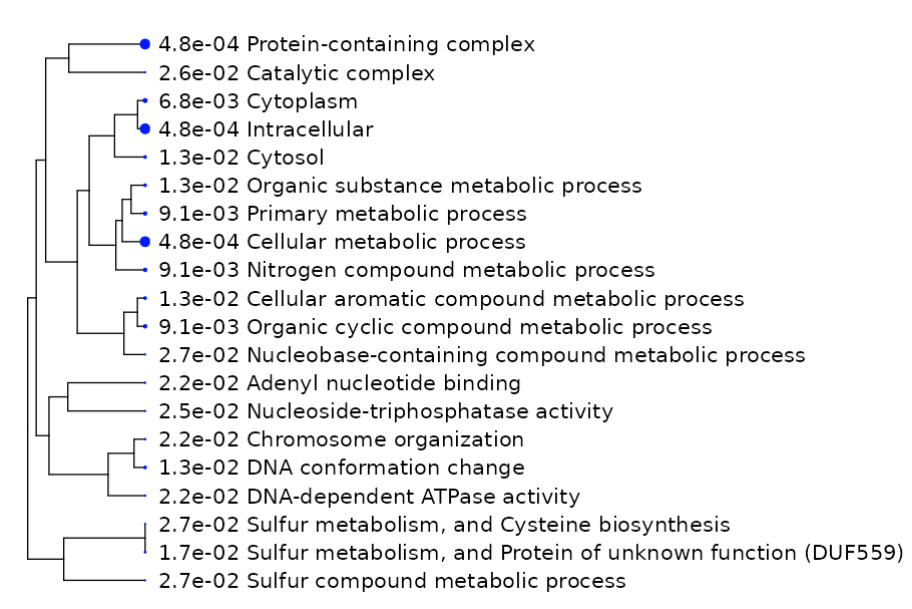



ShinyGO also offers a tree based on hierarchical clustering that summarizes correlations among significant pathways listed in the enrichment tab. Pathways sharing many genes are clustered together within this visualization. The size of the dots at the tips is relative to the P-values.



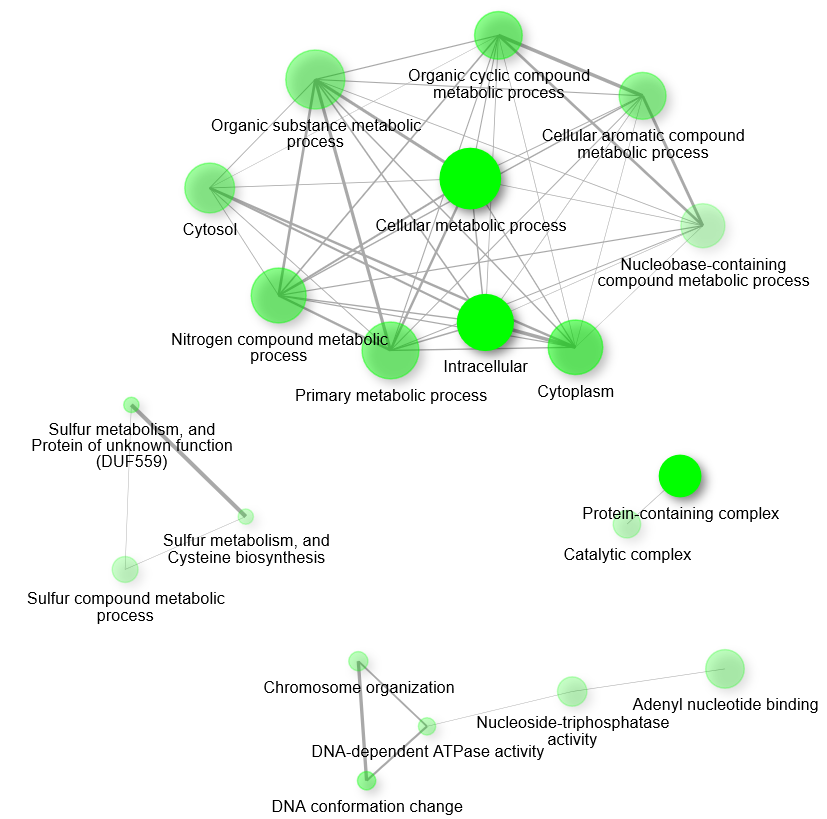



Selecting the Network tab generates a visual network diagram depicting connections between enriched pathways. The node opacity reflects the significance of P-values, where higher opacity indicates increased significance.


Don't hesitate to explore additional features in ShinyGO:
  1. Conduct KEGG pathway enrichment analysis by choosing KEGG within the pathway databases.
  2. Analyze gene positions within the genome for specific organisms.
  3. Utilize STRING-db enrichment analysis to retrieve protein-protein networks.